# Data Preprocessing

### Imports

In [73]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))

In [74]:
from pathlib import Path as path

from io import StringIO
import itertools as it

from scipy.io import mmread
from typing import Callable, Dict
import pandas as pd


In [75]:
import scipy

In [76]:
scipy.__version__

'1.17.1'

In [77]:
import scanpy as sc
import anndata as ad

In [78]:
from upsetplot import generate_counts
from upsetplot import plot
from matplotlib import pyplot
from upsetplot import UpSet

In [79]:
from stream_qc_minimal import cal_qc, plot_qc

In [80]:
import scib

In [81]:
import itertools as it
from markers import (
    positive_markers, # function to generate a configuration dictionnary from a set of marker genes
    states_and_markers, # Dictionnary containing phenotypes and their marker genes
)

In [82]:
from data_prep import *

In [83]:
import sys

sys.path.insert(0, str(path.cwd() / "src"))
from pipeline_config import load_config

cfg = load_config()  # dataset wybierasz w pipeline_config.toml (`active`) albo env BOOLAI_DATASET
print(cfg.describe())

dataset='hsc_4ds' [integration], samples=['young_A', 'young_B', 'old_A', 'old_B'], method='paga_dpt'


In [84]:
#import lamindb as ln

# Suppress verbose logging from Scanpy
sc.settings.verbosity = 0

# Set figure parameters for clean, minimal plots
sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)

#assert ln.setup.settings.instance.slug == "theislab/sc-best-practices"

#ln.track()

## Helper functions & constants

Input samples (one raw-counts `genes x cells` TSV per batch) are listed in `pipeline_config.toml` (`datasets.<name>.samples`) and exposed as `cfg.samples` / `cfg.sample_names`.

In [85]:
list(zip(cfg.sample_names, cfg.samples))  # (batch label, input file)

[('young_A', 'GSM4443875_young_A_merged.tsv'),
 ('young_B', 'GSM4443876_young_B_merged.tsv'),
 ('old_A', 'GSM4443877_old_A_merged.tsv'),
 ('old_B', 'GSM4443878_old_B_merged.tsv')]

Here we define several helper functions to perform following tasks:
- `createExperimentDataFrame` to build count matrix from GEO record files,
- `createMergedDataset` to create one dataset containing all experiment batches from several files,
- `common_preprocessing` containing data preprocessing steps that are needed for hvg selection, performed on each dataset separately,
- `hvg_scanpy` performing hvg selection with chosen method from predefined set,
- `evaluate_hvg_selection` gathering results from different hvg selection methods.

In [86]:
def createExperimentDataFrame(experiment_id):
    suffixes = ['matrix.mtx.gz', 'genes.tsv.gz', 'barcodes.tsv.gz']
    files = {s: f"{experiment_id}{s}" for s in suffixes}  
    m = mmread(files['matrix.mtx.gz'])
    m = m.toarray()
    df = pd.read_csv(files['genes.tsv.gz'], sep='\t', names=['id', 'gene'])
    a= df['gene'].to_list()
    barcodes = pd.read_csv(files['barcodes.tsv.gz'], sep='\t', header=None)
    b = list(barcodes.values.flatten())
    df = pd.DataFrame(m, index=a, columns=b)
    
    return df

In [87]:
def createMergedDataset(file_names, datasets):
    combined = ad.concat(
        datasets,
        join='inner',      # Keep all genes
        index_unique='_',
        merge="same"
    )
    return combined

In [88]:
def common_preprocessing(adata_original):
    adata = adata_original.copy()
    
    # mitochondrial genes deletion
    adata.var['mt'] = adata.var_names.str.startswith('MT-') 
    # filtering them out
    adata = adata[:, ~adata.var['mt']].copy()
    
    return adata

In [89]:
def hvg_scanpy(adata_original, method) -> list:
    adata = adata_original.copy()
    common_preprocessing(adata)
    # batch_key is also used with a single batch: scanpy then takes the batched path, which drops
    # unexpressed genes before binning (without it flavor="cell_ranger"/"seurat" fails with "Bin edges must be unique")
    batch_key = "batch"
    if method not in [ "pearson_residuals", "seurat_v3", "seurat_v3_paper" ]:
        sc.pp.normalize_total(adata, target_sum=1e4)
        sc.pp.log1p(adata)
        genes = sc.pp.highly_variable_genes(
        adata, 
        flavor=method, 
        batch_key=batch_key,
        inplace=False
    )
    elif method == "pearson_residuals":
        genes = sc.experimental.pp.highly_variable_genes(
        adata, 
        flavor=method,
        n_top_genes = 2000,
        batch_key=batch_key, 
        inplace=False
    )

    else:
        genes = sc.pp.highly_variable_genes(
        adata, 
        flavor=method,
        n_top_genes = 2000,
        batch_key=batch_key,
        inplace=False
    )
        
    return genes

In [90]:
# dictionary containing methods - to be changed
HVG_METHODS: Dict[str, Callable] = {
    "seurat": hvg_scanpy,
    #"scanpy": hvg_scanpy_dispersion,
    'cell_ranger': hvg_scanpy, 
    'seurat_v3':hvg_scanpy, 
    'seurat_v3_paper':hvg_scanpy,
    "pearson_residuals":hvg_scanpy,
    "consensus": lambda data, n: list(set(hvg_seurat_vst(data, n)) & set(hvg_scanpy_dispersion(data, n)))
}

In [91]:
'''def select_hvg(adata, method: str = "seurat", **kwargs):
    if method not in HVG_METHODS:
        raise ValueError(f"Metoda {method} nie jest wspierana. Wybierz z: {list(HVG_METHODS.keys())}")
    
    return hvg_scanpy(adata, method)'''

'def select_hvg(adata, method: str = "seurat", **kwargs):\n    if method not in HVG_METHODS:\n        raise ValueError(f"Metoda {method} nie jest wspierana. Wybierz z: {list(HVG_METHODS.keys())}")\n\n    return hvg_scanpy(adata, method)'

In [92]:
def evaluate_hvg_selection(adata):
    hvg_results = []
    for method in {method for method in HVG_METHODS if method != 'consensus'}:
        hvg = hvg_scanpy(adata, method=method)
        hvg.rename(columns={'highly_variable':method})
        hvg = hvg[method]
        hvg_results.append(hvg)   

### Data download and unpacking

In [13]:
!test -f 'GSE147729_RAW.tar' || \
    wget -O 'GSE147729_RAW.tar' 'https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE147729&format=file' && \
    echo "Import data and Select observarions whose ID starts with Lane1_"

Import data and Select observarions whose ID starts with Lane1_


In [14]:
!test -f 'GSM4443875_young_A_barcodes.tsv.gz' || \
    tar -xvf 'GSE147729_RAW.tar'

In [35]:
!test -f GSE122466_Retina_Batch1_RAW.tsv || echo "Select observarions whose ID starts with Lane1_"

Select observarions whose ID starts with Lane1_


In [36]:
!test -f 'GSE122466_Retina_Batch1_RAW.tsv' || \
    wget -O 'GSE122466_Merged5347cells_RAW.csv.gz' 'https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE122466&format=file&file=GSE122466%5FMerged5347cells%5FRAW%2Ecsv%2Egz' && \
    echo "Import data and Select observarions whose ID starts with Lane1_"

--2026-10-20 11:36:45--  https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE122466&format=file&file=GSE122466%5FMerged5347cells%5FRAW%2Ecsv%2Egz
Translacja www.ncbi.nlm.nih.gov (www.ncbi.nlm.nih.gov)... 34.107.134.59, 2600:1901:0:c831::
Łączenie się z www.ncbi.nlm.nih.gov (www.ncbi.nlm.nih.gov)|34.107.134.59|:443... połączono.
Żądanie HTTP wysłano, oczekiwanie na odpowiedź... 301 Moved Permanently
Lokalizacja: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE122nnn/GSE122466/suppl/GSE122466_Merged5347cells_RAW.csv.gz [podążanie]
--2026-10-20 11:36:45--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE122nnn/GSE122466/suppl/GSE122466_Merged5347cells_RAW.csv.gz
Translacja ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.12, 130.14.250.11, 2607:f220:41e:250::13, ...
Łączenie się z ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.12|:443... połączono.
Żądanie HTTP wysłano, oczekiwanie na odpowiedź... 200 OK
Długość: 10143933 (9,7M) [application/x-gzip]
Zapis do: ‘GSE122466_Merged5347cel

### Data inspection (early exploration steps)

This section contains some explorational steps that should be deleted soon.

In [ ]:
'''%%time
datasets = []
for idx in datasetsIds:
    datasets.append(createExperimentDataFrame(idx))

result = pd.concat((young_A_df, young_B_df))

result.shape, young_A_df.shape, young_B_df.shape

result = df

result.fillna(0, inplace=True)

result = result.apply(pd.to_numeric, downcast='integer')

mask = result.isna()

young_A_df.index

result[~mask]

result.head()

young_B_df.fillna(0, inplace=True)
young_B_df = young_B_df.apply(pd.to_numeric, downcast='integer')

young_B_df.to_csv("GSM4443875_young_B_merged.tsv", sep="\t")

result.to_csv("GSM4443875_merged.tsv", sep="\t")

results = zip(datasetsIds, datasets)
#map(lambda x: x[1].to_csv(x[0] + "merged.tsv", sep="\t"), list(results))

for (idx, df) in results:
    df.to_csv(idx + "merged.tsv", sep="\t")

len(list(results))'''

### Paths setup

In [ ]:
_in_dir = path(".").resolve()
_publish_dir = path(".").resolve()
if not _publish_dir.exists():
    _publish_dir.mkdir()
print(f"Reading data from: {_in_dir.name}")
print(f"Saving processed data to: {_publish_dir.name}")

In [ ]:
infile = _in_dir /'GSM4443875_merged.tsv'
outfile = _publish_dir / "GSM4443875_merged.csv"

### Read in data

In [ ]:
infile = _in_dir / 'GSM4443875_young_B_merged.tsv'

In [ ]:
%%time 
adata = st.read(file_name=infile.as_posix(), workdir='./stream_result')

In [ ]:
adata.obs_names_make_unique()
adata.var_names_make_unique()

In [ ]:
adata

## Dataset Creation

In this section we:
1. Load data from different batches.
2. Preprocess them separately.
3. Merge them into one experimental dataset.

### Multiple datasets

In [47]:
print(cfg.sample_names)

['young_A', 'young_B', 'old_A', 'old_B']


In [48]:
%%time
datasets_adata = []

for batch_id, sample_file in zip(cfg.sample_names, cfg.sample_paths):
    adata = sc.read_csv(sample_file, delimiter="\t")
    adata = adata.T
    adata.obs_names_make_unique()
    adata.var_names_make_unique()
    adata.X = adata.X.astype(int)
    adata.obs['batch'] = batch_id
    adata = preprocess_like_herault_data_preparation(adata, copy=True)
    datasets_adata.append(adata)

/home/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1823: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1825: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1823: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/anndata/_core/anndata.py:1825: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/ann

CPU times: user 52.1 s, sys: 1.5 s, total: 53.6 s
Wall time: 1min 1s


In [22]:
adata

AnnData object with n_obs × n_vars = 4154 × 28692
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'

In [23]:
datasets_adata[0].obs.head()

,batch,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt
AAACCTGAGTTCGATC-1,young_A,2054,7.628031,5003,8.517993,31.421147,43.393964,52.668399,66.620028,218,5.389072,4.357386
AAACCTGCAATCGGTT-1,young_A,1884,7.541683,4708,8.457231,34.430756,46.983857,55.819881,70.029737,176,5.176150,3.738318
AAACCTGCACACGCTG-1,young_A,2295,7.738924,5877,8.678972,26.680279,38.506040,48.987579,64.352561,98,4.595120,1.667517
AAACCTGCACGGATAG-1,young_A,2997,8.005701,9279,9.135617,29.076409,41.825628,51.406402,64.166397,387,5.961005,4.170708
AAACCTGCATCATCCC-1,young_A,3329,8.110728,10987,9.304559,30.618003,43.205607,52.361882,64.831164,297,5.697093,2.703195


In [ ]:
merged_adata = createMergedDataset(cfg.samples, datasets_adata)

In [25]:
merged_adata.var_names

Index(['Xkr4', 'Gm1992', 'Gm37381', 'Rp1', 'Rp1-1', 'Sox17', 'Gm37323',
       'Mrpl15', 'Lypla1', 'Gm37988',
       ...
       'AC125149.1', 'AC125149.2', 'AC125149.4', 'AC234645.1', 'AC168977.2',
       'AC168977.1', 'PISD', 'DHRSX', 'Vmn2r122', 'CAAA01147332.1'],
      dtype='object', length=28692)

In [26]:
merged_adata

AnnData object with n_obs × n_vars = 14915 × 28692
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'mt'

### Single dataset



In [37]:
merged = pd.read_csv("GSE122466_Merged5347cells_RAW.csv.gz", sep=";", index_col=0)

In [38]:
merged.head()

,Lane1_AAACCTGAGATGTCGG,Lane1_AAACCTGCAATCCAAC,Lane1_AAACCTGGTTCCTCCA,Lane1_AAACCTGTCCAATGGT,Lane1_AAACGGGAGGCAATTA,Lane1_AAACGGGCACCAGGCT,Lane1_AAACGGGCACGGCGTT,Lane1_AAACGGGCACTCAGGC,Lane1_AAACGGGCATCCAACA,Lane1_AAACGGGGTCCAAGTT,...,Lane2_TTTGGTTCATAAAGGT,Lane2_TTTGGTTGTGGCCCTA,Lane2_TTTGGTTTCTAACTCT,Lane2_TTTGTCAAGCGTGAAC,Lane2_TTTGTCAAGGGCTCTC,Lane2_TTTGTCAAGTACCGGA,Lane2_TTTGTCACATCGATGT,Lane2_TTTGTCAGTAGAGGAA,Lane2_TTTGTCAGTCATCCCT,Lane2_TTTGTCATCAGTTCGA
Xkr4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Mrpl15,3,0,0,0,1,0,0,0,0,0,...,0,1,1,0,1,0,0,2,1,0
Lypla1,0,0,2,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0
Gm37988,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Tcea1,2,0,5,1,2,4,1,0,0,0,...,1,3,0,1,1,0,1,1,1,0


In [39]:
lane1 = merged[merged.columns[merged.columns.str.startswith("Lane1_")]]
lane1.to_csv("GSE122466_Retina_Batch1_RAW.tsv", sep="\t")

In [53]:
#merged_adata = sc.read_csv("GSE122466_Retina_Batch1_RAW.tsv", delimiter="\t")

In [103]:
adata = sc.read_csv("GSE122466_Retina_Batch1_RAW.tsv", delimiter="\t")
adata = adata.T
adata.obs_names_make_unique()
adata.var_names_make_unique()
adata.X = adata.X.astype(int)
adata.obs['batch'] = "0"
merged_adata = preprocess_like_herault_data_preparation(adata, copy=True)

### Export

In [104]:
merged_adata.write_h5ad(cfg.path("merged_h5ad"))

In [105]:
merged_adata.to_df().to_csv(cfg.path("merged_csv"))

### QC v2

This section contains QC performed in original paper style, although implemented in `scanpy`.  
It is in the end visualized in same-styled **QC** plots.  
**QC processing should be performed per dataset!**.

In [60]:
from stream_qc_minimal import cal_qc, plot_qc

In [61]:
sample_adata = merged_adata.copy()

In [64]:
cal_qc(sample_adata, assay="rna")

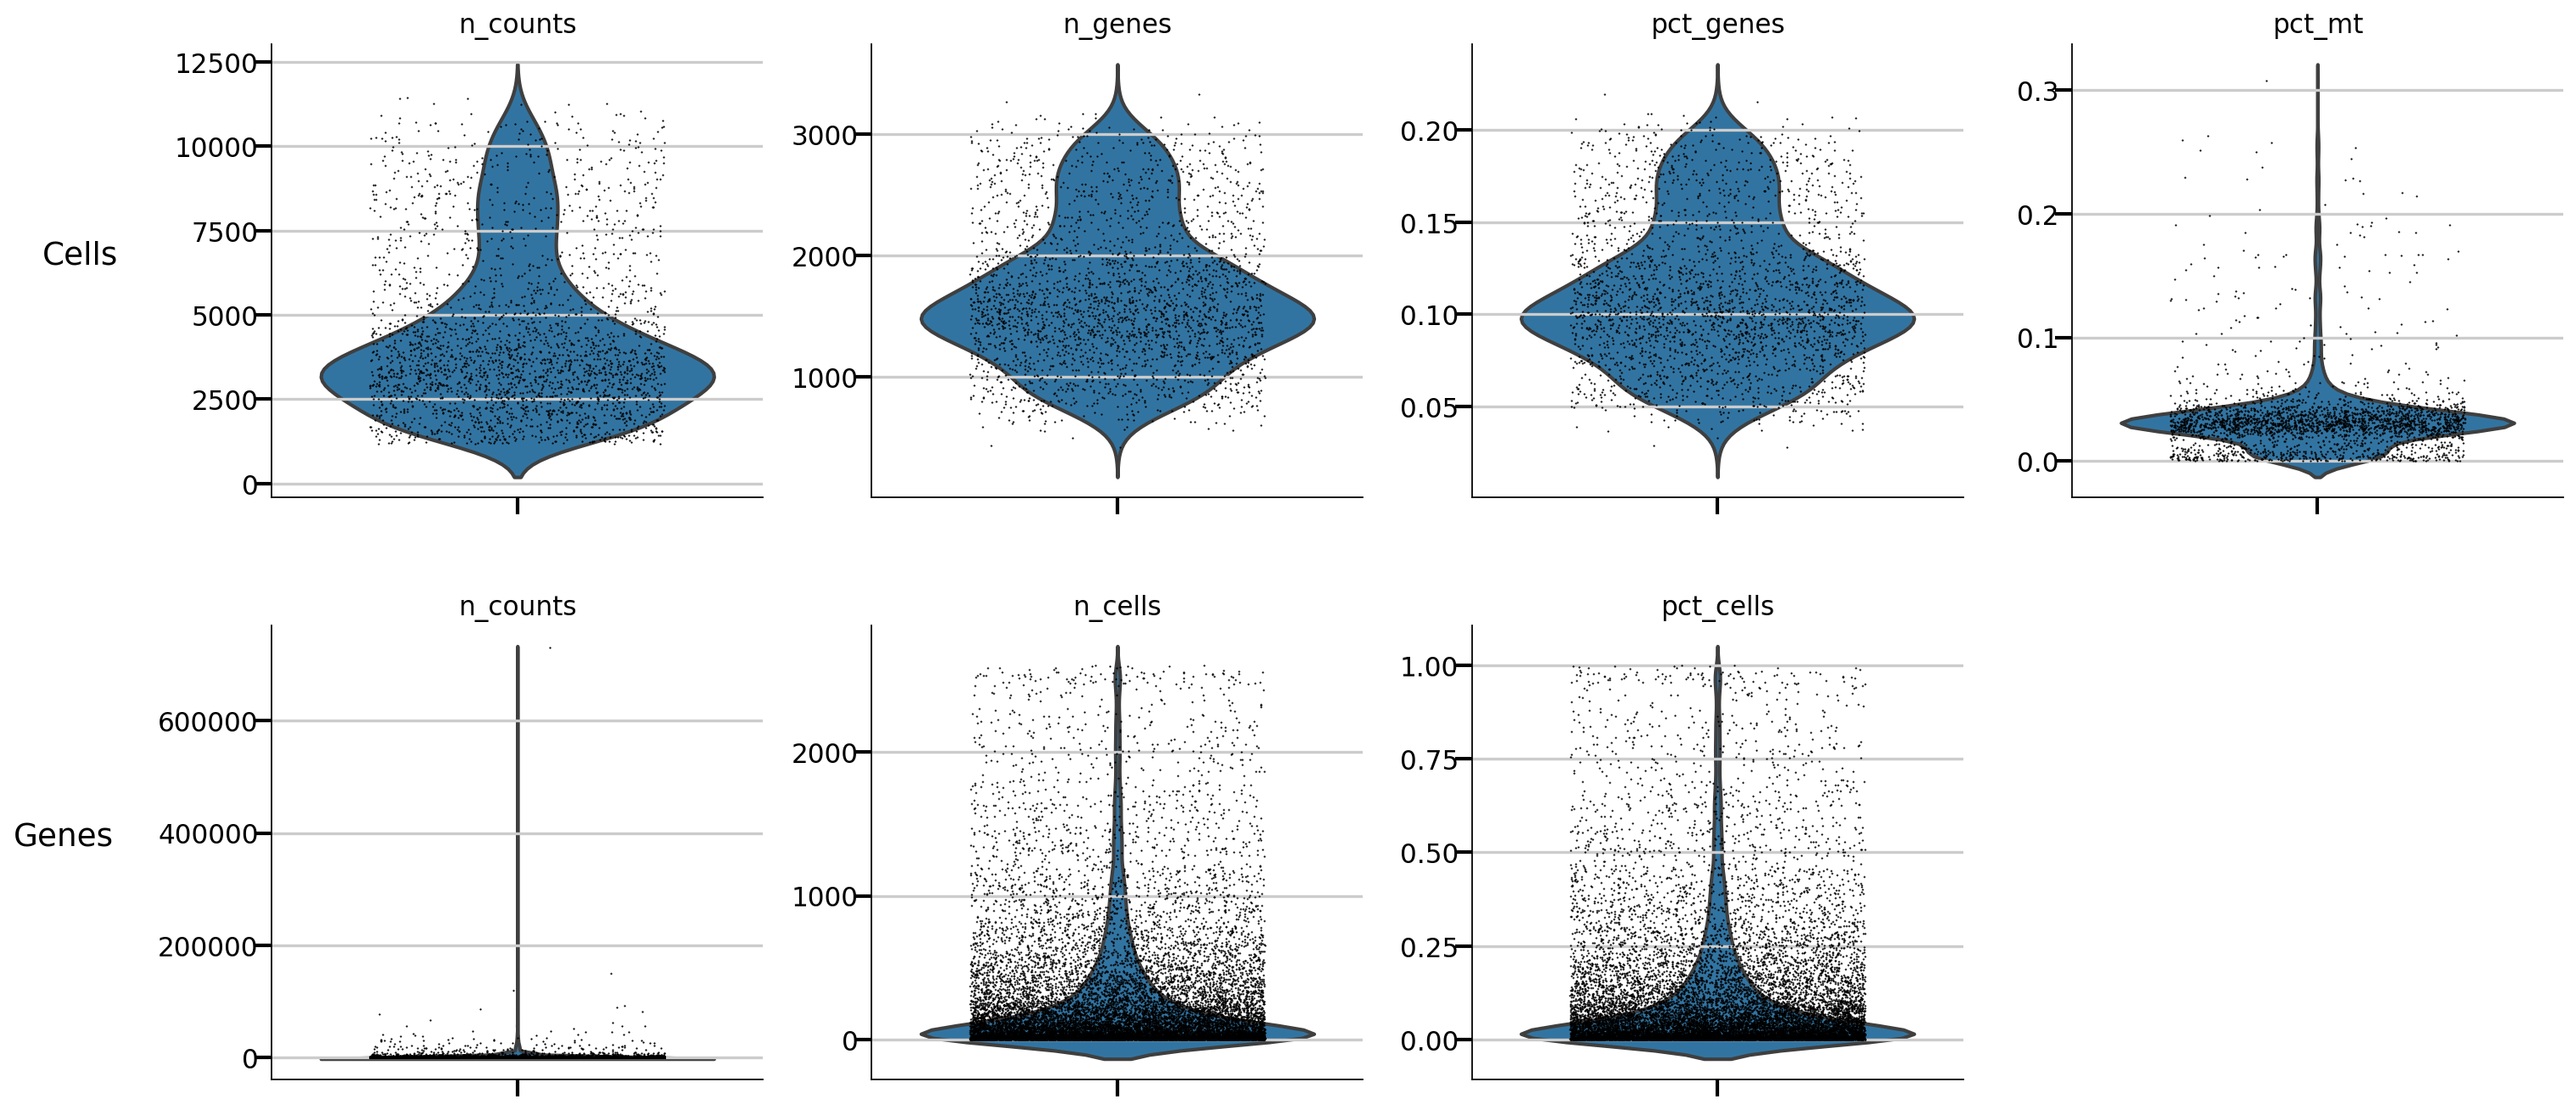

In [65]:
plot_qc(sample_adata, jitter=0.3)

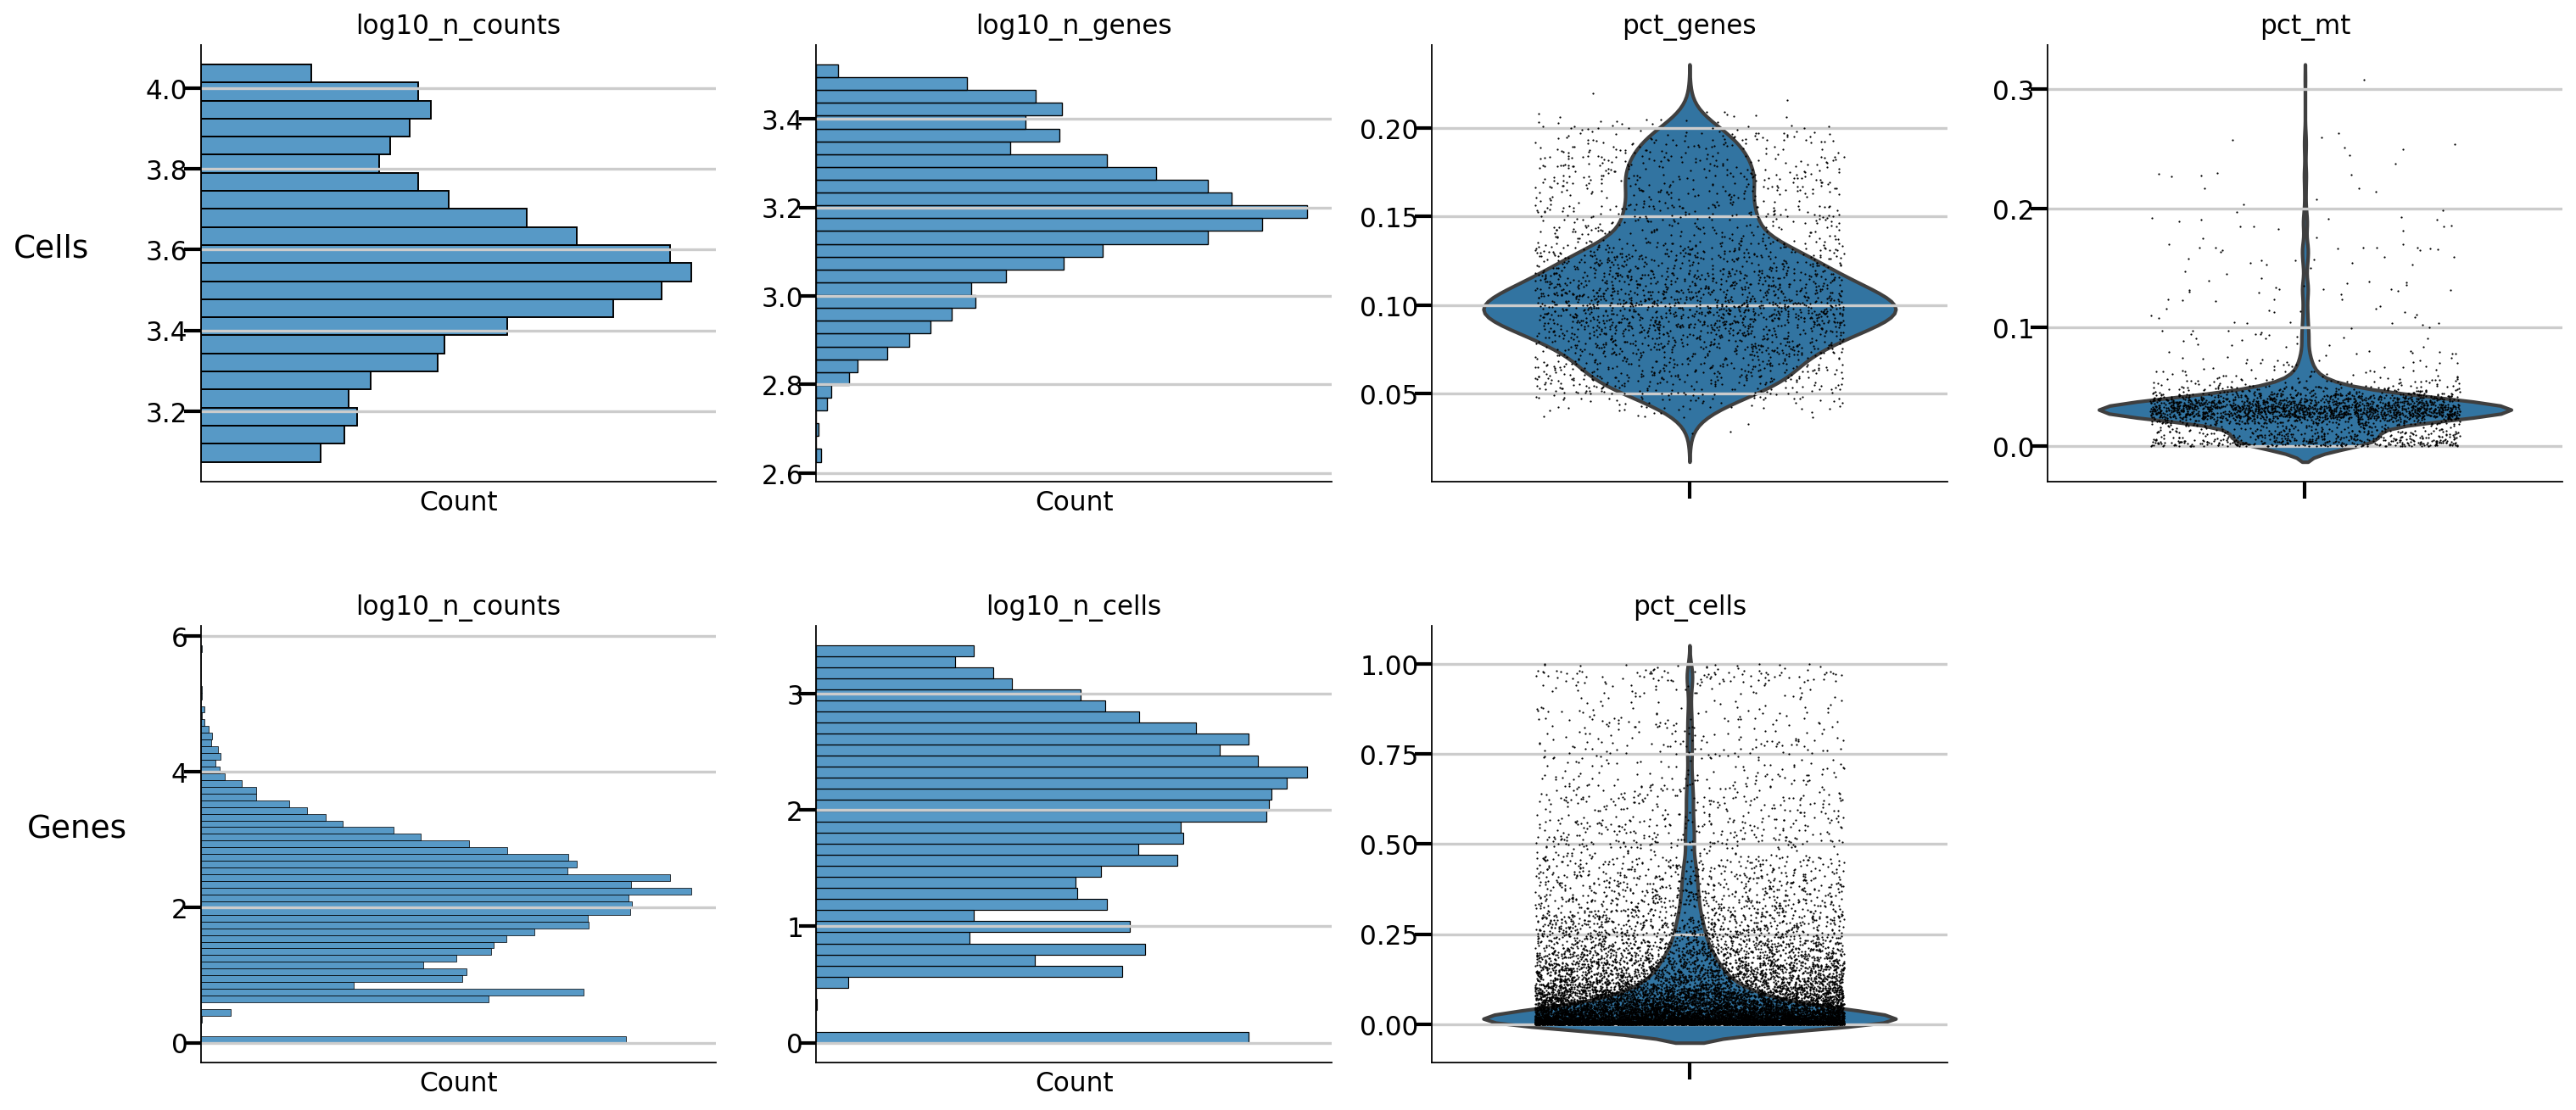

In [66]:
plot_qc(sample_adata, jitter=0.3, log_scale=[0,1,4,5], hist_plot=[0,1,4,5])

### Clusterization

In [ ]:
# setting highly variable as highly deviant to use scanpy 'use_highly_variable' argument in sc.pp.pca
#adata.var["highly_variable"] = adata.var["highly_deviant"]
#sc.pp.pca(adata, svd_solver="arpack", mask_var="highly_variable")

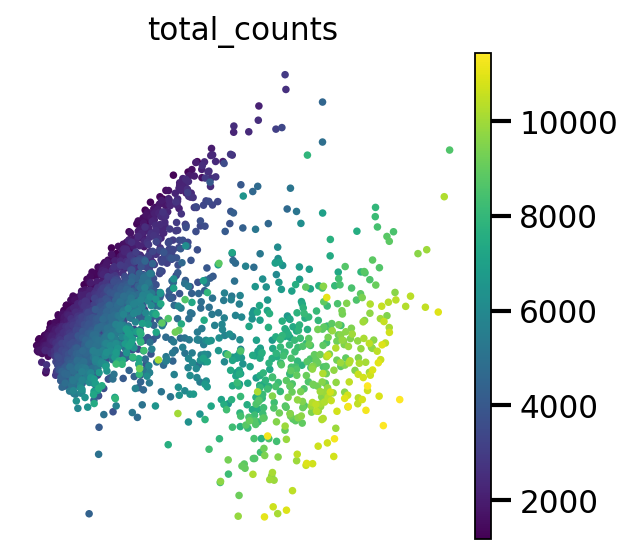

In [68]:
sc.pl.pca_scatter(merged_adata, color="total_counts")

In [69]:
sc.pp.neighbors(merged_adata)
sc.tl.umap(merged_adata)

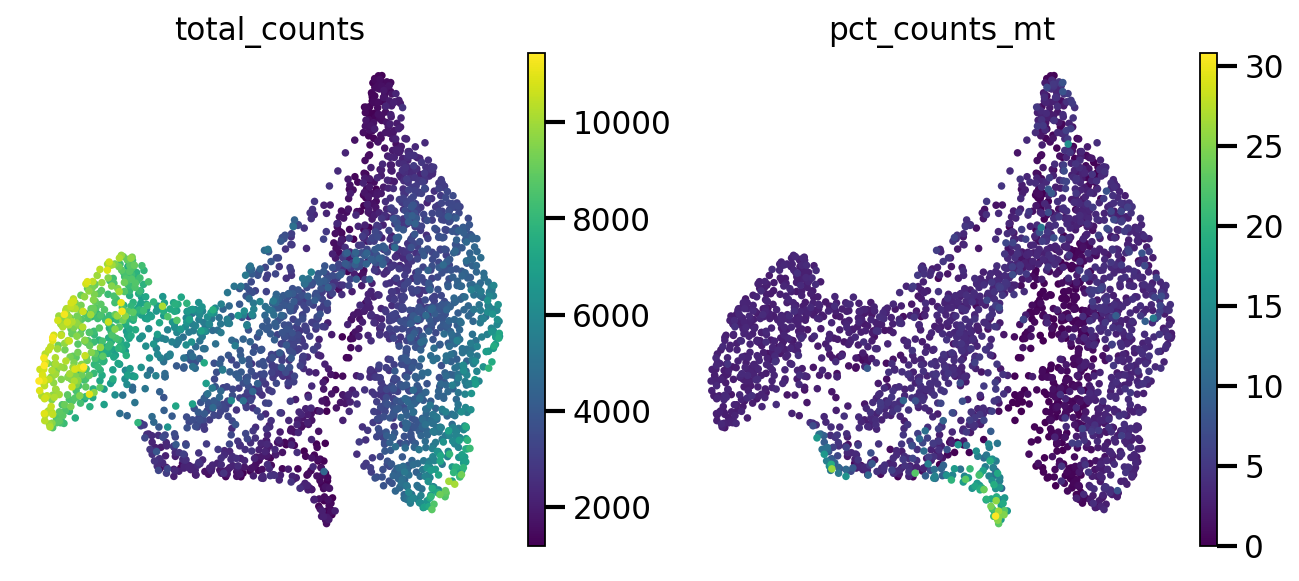

In [70]:
sc.pl.umap(
    merged_adata,
    color=["total_counts", "pct_counts_mt"],
)

### HVG selection

Here we select Highly Variable Genes (HVGs) using different methods implemented in `scanpy` package.

In [97]:
merged_adata = sc.read_h5ad(cfg.path("merged_h5ad"))

In [106]:
hvg_results = []

In [107]:
%%time
for method in {method for method in HVG_METHODS if method != 'consensus'}:
    hvg = hvg_scanpy(merged_adata, method=method)
    hvg.rename(columns={'highly_variable':method}, inplace=True)
    hvg = hvg[method]
    hvg_results.append(hvg)

CPU times: user 4.86 s, sys: 1.3 s, total: 6.17 s
Wall time: 6.19 s


In [108]:
eval_results = pd.concat(hvg_results, axis=1)

In [109]:
eval_results

,seurat_v3_paper,seurat,pearson_residuals,seurat_v3,cell_ranger
Xkr4,False,False,False,False,False
Mrpl15,False,False,False,False,False
Lypla1,False,False,False,False,True
Gm37988,False,False,True,False,False
Tcea1,False,False,False,False,False
...,...,...,...,...,...
Kazald1,False,False,False,False,False
Hps6,False,False,False,False,False
Nfkb2,False,False,False,False,False
Gm26792,False,False,False,False,False


In [110]:
eval_results['seurat_v3_paper'].sum()

np.int64(2000)

In [111]:
cols = list(eval_results.columns)

In [112]:
results_without_nulls = eval_results[eval_results[cols].any(axis=1)]

In [113]:
true_counts = eval_results[cols].sum(axis=1)

In [114]:
df_filtered = eval_results[true_counts > 1]

In [115]:
result = df_filtered.value_counts(subset=cols).sort_index()

In [116]:
result

seurat_v3_paper  seurat  pearson_residuals  seurat_v3  cell_ranger
False            False   True               False      True            56
                 True    False              False      True           725
                         True               False      False          139
                                                       True           325
True             False   False              True       False          760
                                                       True            91
                         True               True       False          120
                                                       True            29
                 True    False              True       False           94
                                                       True            82
                         True               True       False           97
                                                       True           727
Name: count, dtype: int64

Results of HVGs selection are gathered and filtered to present numbers of exclusive intersections of identified genes by different methods.  
They are visualized in form of so-called UpSet plot.

/home/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/home/jasiek/anaconda3/envs/scBoolSeq/lib/python3.11/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are 

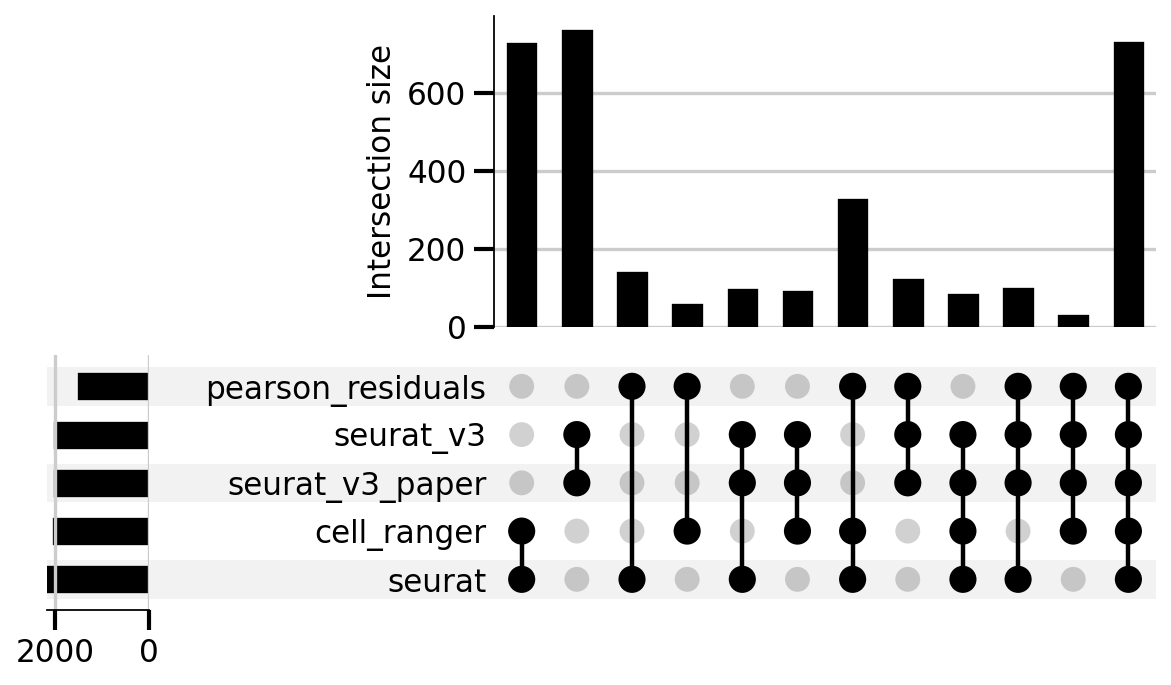

In [117]:
ax_dict = UpSet(result).plot()

In [118]:
from markers_retinal import (
    positive_markers, # function to generate a configuration dictionnary from a set of marker genes
    states_and_markers, # Dictionnary containing phenotypes and their marker genes
)

In [119]:
hvgs = true_counts[true_counts == 5].index

In [120]:
marker_genes = pd.Series(list(set(it.chain.from_iterable(states_and_markers.values()))))
len(marker_genes)

22

In [121]:
100 * marker_genes.isin(hvgs).mean()

np.float64(81.81818181818183)

In [122]:
marker_genes[~marker_genes.isin(hvgs) & marker_genes.isin(merged_adata.var_names)]

1     Pou4f2
11      Rbp4
14      Pax6
15     Prox1
dtype: object

In [ ]:
'''export_markers = adata.uns['var_genes'].copy(deep=True)
export_markers = export_markers.append(pd.Index(marker_genes[~marker_genes.isin(adata.uns["var_genes"])]))
export_markers'''

In [123]:
merged_adata.var

,mt,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts
Xkr4,False,29,0.011137,0.011075,98.886329,29,3.401197
Mrpl15,False,760,0.359831,0.307360,70.814132,937,6.843750
Lypla1,False,519,0.236559,0.212333,80.069124,616,6.424869
Gm37988,False,4,0.001536,0.001535,99.846390,4,1.609438
Tcea1,False,1136,0.665515,0.510134,56.374808,1733,7.458186
...,...,...,...,...,...,...,...
Kazald1,False,0,0.000000,0.000000,100.000000,0,0.000000
Hps6,False,0,0.000000,0.000000,100.000000,0,0.000000
Nfkb2,False,0,0.000000,0.000000,100.000000,0,0.000000
Gm26792,False,0,0.000000,0.000000,100.000000,0,0.000000


In [124]:
export_markers = hvgs

In [125]:
export_markers = hvgs.append(pd.Index(marker_genes[~marker_genes.isin(hvgs) & marker_genes.isin(merged_adata.var_names)]))

In [126]:
len(export_markers)

731

In [ ]:
'''n_batches = adata.var["highly_variable_nbatches"].value_counts()
ax = n_batches.plot(kind="bar")
n_batches'''

### Exporting HVGs to file

In [ ]:
# extract the genes index
var_genes = adata.uns["var_genes"]
var_genes

In [ ]:
[f.name for f in _publish_dir.glob("*csv")]

In [ ]:
adata.to_df()[export_markers].to_csv(outfile.as_posix())

In [ ]:
[f.name for f in _publish_dir.glob("*csv")]

Here we save two files used by the rest of the pipeline: `counts_hvgs.csv` (raw counts of the HVG + marker set, used by `1. Cell Annotation`) and `dataset_hvgs.csv` (the same genes, log-normalised; used by `3. Final Cell Annotation` and `4.5. Phenotype Observations`).

In [127]:
adata_hvg = merged_adata[:,export_markers].copy()

In [62]:
adata_hvg.X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 3, 0, ..., 0, 0, 1],
       ...,
       [0, 3, 0, ..., 0, 4, 1],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 1, 1]], shape=(14915, 488))

In [128]:
adata_hvg.to_df().to_csv(cfg.path("counts_hvgs_csv"))

In [129]:
normalize_log_scanpy(adata_hvg, target_sum=1e4)

In [130]:
adata_hvg.to_df().to_csv(cfg.path("hvgs_csv"))